# Intensity-power fit of the exciton and biexciton spectrum

While trying to test the fitting and plotting functions in the library, we've found that it's helpful to work with synthetic data. We can define parameters of our data and see if the functions we have defined can extract them as a simple sanity check that they indeed work as intended. In this notebook, we will be recreating (part of) the spectrum from this paper on PL from 1L-WSe2 [1].

We extract the numbers provided by the authors and use some estimations from our own measurements to put realistic spectra counts to the data. We first try this without noise and later with noise. 

## References
[1] Ye, Z. et al. Efficient generation of neutral and charged biexcitons in encapsulated WSe2 monolayers. Nat Commun 9, 3718 (2018).

In [1]:
import leman as lm
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from matplotlib.colors import Normalize

We define our spectral features, like the center energy and the FWHM. We also define our power coefficient $\alpha$ that the authors report while performing power-dependent scans.

In [15]:
E_X = 1.723 # eV
E_XX = 1.703 # eV Nat. Comm 9, 3718 (2018) 
E_D = 1.681 #  eV
delta_X = 5e-3 # eV
delta_XX = 5e-3 # eV
delta_D = 3e-3
alpha_X = 1.22
alpha_XX = 1.96
alpha_D = 1.03 

Now we move on to defining the kind of peak intensity counts we expect to see. From our own experiments performed at LANES, using an incident power of $4.6\;\mathrm{\mu W}$ yields something like 50 counts for the exciton and 15 counts for biexciton features.

In [16]:
powers = np.geomspace(1, 90, 15) # the powers we will apply to the sample
P_ref = 4.6 # uW

In [17]:
powers = np.geomspace(1, 90, 15) # the powers we will apply to the sample
P_ref = 4.6 # uW

def model_spectra(energy, powers):
    """(n_pixels, n_sweeps) expected counts: X + XX at each power."""
    amp_X  = 50  * (powers / P_ref)**alpha_X
    amp_XX = 15 * (powers / P_ref)**alpha_XX
    amp_D = 10 *(powers/P_ref) ** alpha_D
    return np.stack(
        [lm.fitting.lorentzian(energy, a, E_X, delta_X)
         + lm.fitting.lorentzian(energy, b, E_XX, delta_XX)
         + lm.fitting.lorentzian(energy, c, E_D, delta_D)
         for a, b, c in zip(amp_X, amp_XX, amp_D)], axis=1)

def detector_counts(signal, rng, read, gain, bias):
    """Shot noise in electrons, read noise and bias in counts, rounded."""
    return (rng.poisson(signal * gain) / gain
            + rng.normal(0.0, read, signal.shape) + bias).round()

In [18]:
# Noise parameters
bias = 600
gain = 3 # overall photon -> electron number (including analog gain)
read= 1.0
rng = np.random.default_rng(0)

## Noise-less spectra

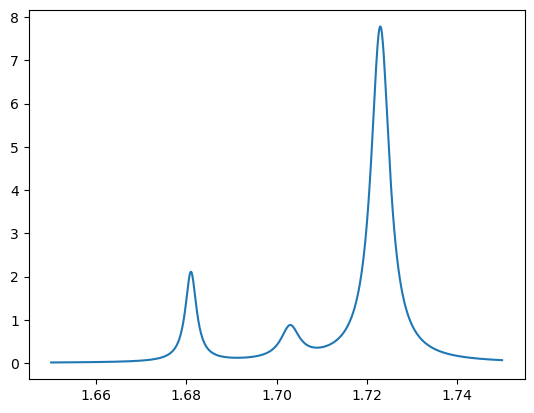

In [20]:
energy=np.linspace(1.65, 1.75, 1000)
spectra = model_spectra(energy, powers = powers)

fig, ax = plt.subplots()
ax.plot(energy, spectra[:,0])

## Noisy spectra

Now we add the noise

In [21]:
noisy = detector_counts(signal = spectra,
                        rng = np.random.default_rng(0),
                        read = read,
                        gain = gain,
                        bias = bias)

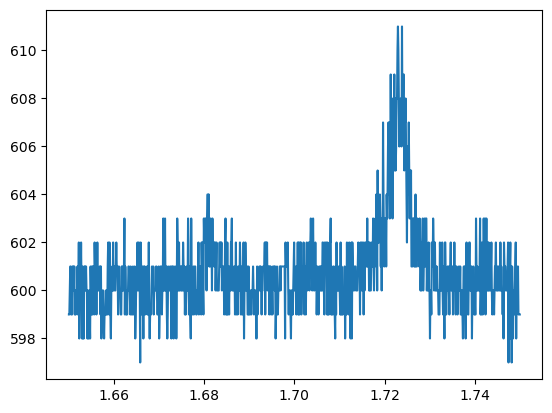

In [24]:
fig, ax = plt.subplots()
ax.plot(energy, noisy[:,0])

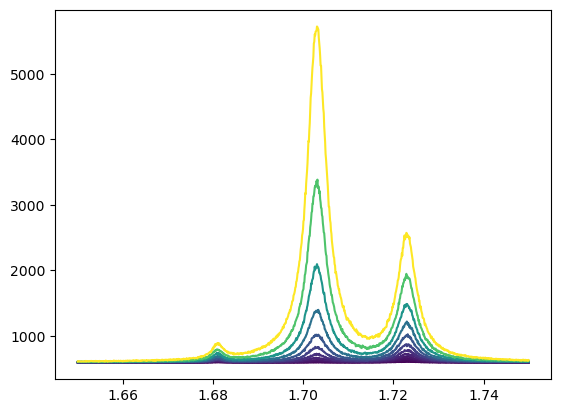

In [27]:
fig, ax = plt.subplots()

norm = Normalize(vmin = min(powers), vmax=max(powers))
sm = mpl.cm.ScalarMappable(cmap = 'viridis', norm = norm)
for i, s in enumerate(noisy.T):
    ax.plot(energy, noisy.T[i], color = sm.to_rgba(powers[i]))

## Sanity check: recover the power-law exponents with the leman pipeline

Now we will use the `SyntheticSpectralSweep` which allows us to load synthetic data as if it were a real measured sweep and test our functions on it.

The intensity of a species grows with excitation power as a power law, $I = A\,P^{\alpha}$, with $\alpha \approx 1$ for the exciton and $\alpha \approx 2$ for the biexciton. `extract_amplitude_scaling` fits exactly this model, as a straight line on a log-log plot.

1. `SyntheticSpectralSweep` puts the arrays into a sweep object.
2. `plot_spectral_series` draws the power series.
3. `track_multi_peak_energies` fits both peaks together at every power.
4. `extract_amplitude_scaling` fits $\log I = \alpha \log P + \log A$ to each peak's amplitude.

If the fitted exponents match the ones put in, the fitting chain is working.

In [52]:
# wvl holds energies in eV, hence energy=.
synth = lm.SyntheticSpectralSweep(
    noisy,
    energy       = energy,
    parameters   = {"Excitation Power": powers},
    spectra_type = "PL",
    sweep        = "power",
)
synth

SyntheticSpectralSweep — 15 sweeps × 1000 pixels  [Photoluminescence]
  File        : <synthetic>
  λ range     : 708.5 – 751.4 nm
  Energy range: 1.650 – 1.750 eV
  Sweep       : power — 1 → 90 µW
  Power       : 1.0 → 90.0 µW
  Varying     : Excitation Power
  Jacobian    : not applied

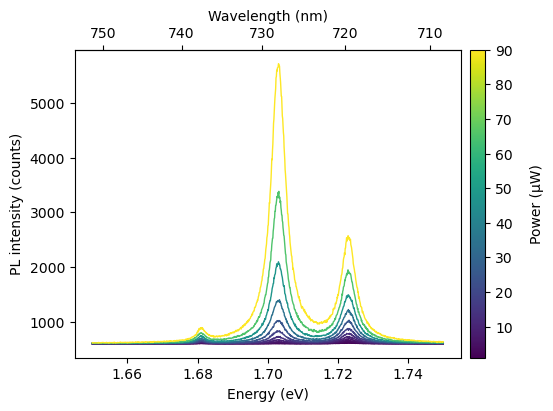

In [53]:
# The power series, one line per power, coloured by power.
series = lm.plotting.plot_spectral_series(synth, twin_axis=True, cmap = 'viridis')

In [54]:
# Fit both peaks together at every power, seeded at the energies put in.
# The result holds one PeakTrack per species, in seed order: X, then XX.
tracks = lm.fitting.track_multi_peak_energies(
    synth, seeds=[E_X, E_XX, E_D],
    center_tol=0.005,           # less than half the 22 meV XX–D spacing
    fwhm_seed=0.005,            # close to the real 3–5 meV widths
    fwhm_range=(1e-6, 0.15),    # lets the Gaussian part vanish for pure Lorentzians
)
track_X, track_XX, track_D = tracks.tracks
tracks

MultiPeakTrackResult (3 species, 15 sweep points, 15 converged)

In [55]:
# Power-law fit to each peak's amplitude, over every power.
# index_ranges rather than coord_ranges: the fit runs on log(P), and
# coord_ranges is compared against log(P), not P, so (1, 6) would select
# only P >= e. One inclusive index range covers all points.
all_points = [(0, synth.n_sweeps - 1)]
scaling_X  = lm.fitting.extract_amplitude_scaling(track_X,  index_ranges=all_points)
scaling_XX = lm.fitting.extract_amplitude_scaling(track_XX, index_ranges=all_points)
scaling_D = lm.fitting.extract_amplitude_scaling(track_D, index_ranges=all_points)

for name, alpha_in, result in [("X",  alpha_X,  scaling_X),
                               ("XX", alpha_XX, scaling_XX),
                               ("D", alpha_D, scaling_D)]:
    seg = result.segments[0]
    print(f"{name:>2}: alpha in = {alpha_in:.3f}   "
          f"fitted = {seg.exponent:.4f} ± {seg.exponent_err:.1e}   "
          f"R² = {seg.r_squared:.6f}")

 X: alpha in = 1.220   fitted = 1.2117 ± 4.2e-03   R² = 0.999844
XX: alpha in = 1.960   fitted = 1.8848 ± 2.5e-02   R² = 0.997795
 D: alpha in = 1.030   fitted = 1.0080 ± 9.4e-03   R² = 0.998861


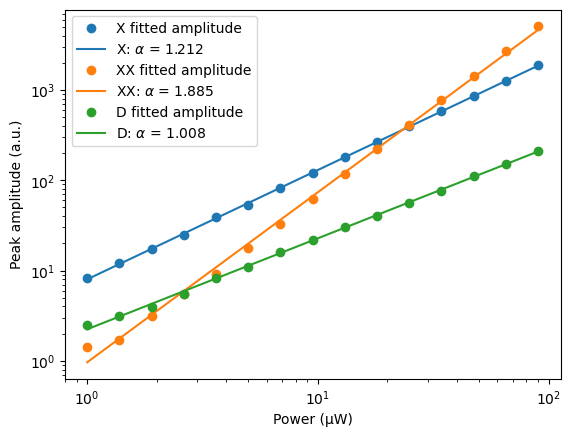

In [56]:
# Fitted amplitude against power on log-log axes, with each fitted line
# I = exp(intercept) · P^alpha drawn through it.
fig, ax = plt.subplots()
for name, color, track, result in [("X",  "C0", track_X,  scaling_X),
                                   ("XX", "C1", track_XX, scaling_XX),
                                   ("D", "C2", track_D, scaling_D)]:
    seg = result.segments[0]
    ax.plot(track.sweep_values, track.peak_amplitudes, "o",
            color=color, label=f"{name} fitted amplitude")
    ax.plot(track.sweep_values,
            np.exp(seg.intercept) * track.sweep_values**seg.exponent,
            "-", color=color,
            label=rf"{name}: $\alpha$ = {seg.exponent:.3f}")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(f"{synth.sweep_label} ({synth.sweep_unit})")
ax.set_ylabel("Peak amplitude (a.u.)")
ax.legend()